# Seen: estimating the loan size a woman entrepreneur can raise

**Student:** MUTONI Keira

**Mission.** I am building an ML-powered credit model that uses mobile money, cooperative and informal trading data to unlock capital for women entrepreneurs in emerging markets, because they are not unbankable, just unseen.

**The question this notebook answers.** Given what a woman-led business looks like (country, business activity, repayment schedule, loan term, how many women borrow together, and whether she has borrowed before), how much money is she likely to raise? The answer is a dollar amount, so this is a regression problem.

**Who uses it.** A loan officer at a cooperative or microfinance partner, or the entrepreneur herself, before a loan request is posted. A request that is far above what similar women usually raise is likely to stall, and one far below leaves money on the table. The estimate helps size the request.

## 1. Where the data comes from

I use **Kiva Crowdfunding loans** (`kiva_loans.csv`), published by Kiva for the "Data Science for Good: Kiva Crowdfunding" challenge: https://www.kaggle.com/datasets/kiva/data-science-for-good-kiva-crowdfunding

How it was collected: every row is a real loan request posted on kiva.org between January 2014 and July 2017. Kiva's field partners (microfinance institutions, cooperatives and social enterprises) meet the borrowers, record the business activity, the loan terms and the group of borrowers, and post the request. Lenders then fund it in 25 dollar shares. The full file has 671,205 loans and 20 columns.

Kiva covers informal trading (retail stalls, food selling, tailoring) and group loans run through cooperatives and women's groups, which are two of the three data sources in my mission. It does not contain mobile money transactions, so that part stays future work.

To keep the repository small, `prepare_data.py` keeps the 173,038 loans from the 30 African countries and drops only the free-text `use` column. Everything else is filtered below, so every decision is visible. I focus on Africa because it is where mobile money is most widely used, so it is where my mission would start.

In [1]:
from pathlib import Path
import io
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
SEED = 7
sns.set_theme(style="ticks", palette="crest")
plt.rcParams["figure.dpi"] = 110

API = Path("../API")
(API / "data").mkdir(parents=True, exist_ok=True)

In [2]:
loans = pd.read_csv("kiva_africa_loans.csv.gz")
print(f"{loans.shape[0]:,} loans and {loans.shape[1]} columns")
loans.head(3)

173,038 loans and 19 columns


,id,funded_amount,loan_amount,activity,sector,country_code,country,region,currency,partner_id,posted_time,disbursed_time,funded_time,term_in_months,lender_count,tags,borrower_genders,repayment_interval,date
0,1080148,250.0,250.0,Services,Services,KE,Kenya,NaN,KES,NaN,2014-01-01 10:06:19+00:00,2014-01-30 01:42:48+00:00,2014-01-29 14:14:57+00:00,4.0,6,NaN,female,irregular,2014-01-01
1,653185,250.0,250.0,Fruits & Vegetables,Food,KE,Kenya,Voi,KES,164.0,2014-01-02 06:59:33+00:00,2013-12-12 08:00:00+00:00,2014-01-02 18:40:01+00:00,13.0,7,#Vegan,female,irregular,2014-01-02
2,653170,3175.0,3175.0,Butcher Shop,Food,TZ,Tanzania,Dar es Salaam,TZS,87.0,2014-01-02 06:26:40+00:00,2013-12-26 08:00:00+00:00,2014-01-29 16:05:19+00:00,10.0,93,"#Parent, #Repeat Borrower, #Schooling, user_fa...","male, male, male, male, male",monthly,2014-01-02


In [3]:
overview = pd.DataFrame({
    "dtype": loans.dtypes.astype(str),
    "missing": loans.isna().sum(),
    "missing %": (loans.isna().mean() * 100).round(1),
    "distinct": loans.nunique(),
})
overview

,dtype,missing,missing %,distinct
id,int64,0,0.0,173038
funded_amount,float64,0,0.0,452
loan_amount,float64,0,0.0,438
activity,str,0,0.0,158
sector,str,0,0.0,15
country_code,str,8,0.0,29
country,str,0,0.0,30
region,str,20615,11.9,2270
currency,str,0,0.0,22
partner_id,float64,8372,4.8,155


## 2. Keeping only loans led by women

`borrower_genders` lists every borrower in the loan, for example `"female, female, female"` for a group of three women. I count the women and men in each loan and keep the loans where every borrower is a woman. The number of women also becomes a feature: `borrower_count`.

In [4]:
genders = loans["borrower_genders"].fillna("")
women = genders.str.count(r"\bfemale\b")
men = genders.str.count(r"\bmale\b")

print("Loans with no gender recorded:", int((women + men == 0).sum()))
print("Loans with at least one man:  ", int((men > 0).sum()))
print("Loans led only by women:      ", int(((women > 0) & (men == 0)).sum()))

data = loans[(women > 0) & (men == 0)].copy()
data["borrower_count"] = women[data.index]
print(f"\nKept {len(data):,} loans ({len(data) / len(loans):.0%} of African loans are led only by women)")

Loans with no gender recorded: 1612
Loans with at least one man:   65708
Loans led only by women:       105718

Kept 105,718 loans (61% of African loans are led only by women)


## 3. Cleaning

**Missing values.** I do not drop rows because of missing values. The two columns with gaps are handled like this:

* `tags` is empty for about a third of the loans. I only use it to know whether the borrower has borrowed before (the `#Repeat Borrower` tag). An empty tag list means Kiva recorded no tag, so the flag is 0 for those rows.
* `partner_id` has a few gaps, but I do not use it as an input (see Section 5), so the gaps do not matter.

The pipelines still contain imputers (median for numbers, most frequent for text), so a future upload with a blank cell is filled in, not thrown away.

In [5]:
data["repeat_borrower"] = data["tags"].fillna("").str.contains("#Repeat Borrower").astype(int)
data["posted_time"] = pd.to_datetime(data["posted_time"])

print("Duplicated loan ids:", int(data["id"].duplicated().sum()))
print("Loans with amount <= 0:", int((data["loan_amount"] <= 0).sum()))
print("Loan terms above 60 months:", int((data["term_in_months"] > 60).sum()))
print(f"Repeat borrowers: {data['repeat_borrower'].mean():.1%}")

Duplicated loan ids: 0
Loans with amount <= 0: 0
Loan terms above 60 months: 198
Repeat borrowers: 14.4%


There are no duplicates and no zero amounts. Two more things need fixing:

* A handful of loans have terms of 5 to 12 years. For a microloan that is unusual and a woman applying today would not pick it, so I remove loans longer than 60 months and use 60 as the upper limit in the API.
* Five countries have fewer than 30 women-led loans (Cote d'Ivoire has a single loan of 50,000 dollars). The model cannot learn a reliable price level from so few loans, so I keep only countries with at least 30 loans. The API then only accepts those countries.

I also put the newest weeks aside (loans posted from 1 June 2017). They act as "new data that arrives later", which I upload to the `/retrain` endpoint of the API.

In [6]:
data = data[data["term_in_months"] <= 60]
loans_per_country = data["country"].value_counts()
too_few = loans_per_country[loans_per_country < 30]
print("Countries removed:", too_few.to_dict())
data = data[data["country"].isin(loans_per_country[loans_per_country >= 30].index)]

cutoff = pd.Timestamp("2017-06-01", tz="UTC")
newest = data[data["posted_time"] >= cutoff]
data = data[data["posted_time"] < cutoff].copy()

raw_columns = [c for c in loans.columns]
newest[raw_columns].to_csv(API / "sample_new_loans.csv", index=False)
print(f"Modelling rows: {len(data):,}  |  new rows saved for retraining: {len(newest):,}")

Countries removed: {'Burundi': 29, 'Somalia': 15, 'Congo': 12, 'Namibia': 4, "Cote D'Ivoire": 1}


Modelling rows: 101,857  |  new rows saved for retraining: 3,602


## 4. Exploring the data

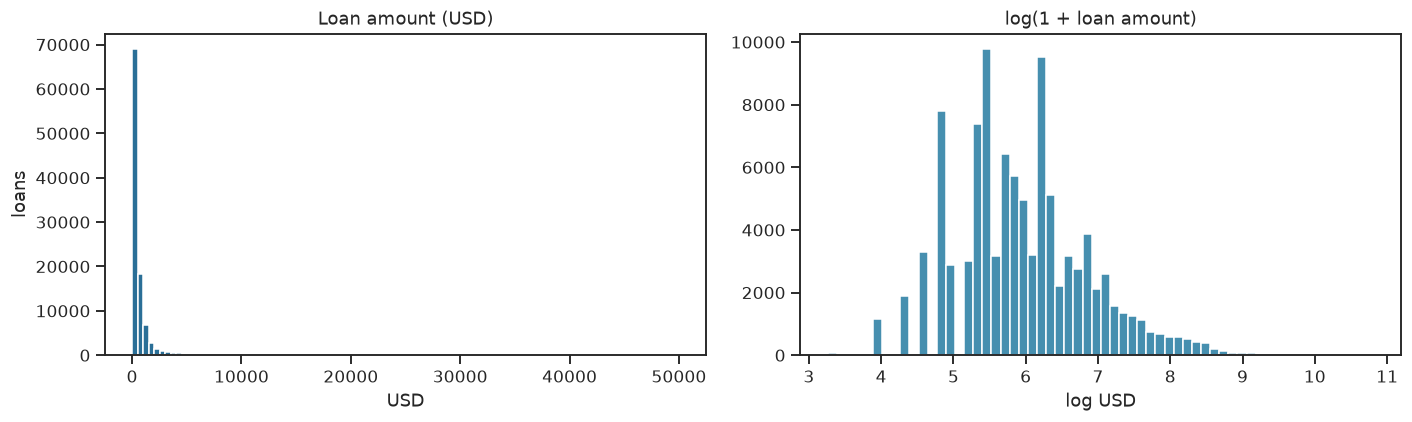

count    101857.0
mean        624.0
std        1003.0
min          25.0
25%         200.0
50%         350.0
75%         650.0
max       50000.0


In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4))
left.hist(data["loan_amount"], bins=100, color="#2a6f97")
left.set(title="Loan amount (USD)", xlabel="USD", ylabel="loans")
right.hist(np.log1p(data["loan_amount"]), bins=60, color="#468faf")
right.set(title="log(1 + loan amount)", xlabel="log USD")
plt.tight_layout()
plt.show()
print(data["loan_amount"].describe().round(0).to_string())

**What I see.** Loan amounts are very right-skewed. Half of the loans are 350 dollars or less, but a few group loans reach tens of thousands, so the raw histogram is one tall bar on the left. On the log scale the shape is close to a bell curve.

**What I decide.** I predict `log(1 + loan_amount)` and turn the answer back into dollars at the end. With raw dollars, the squared error would be ruled by a few very large loans and the model would care little about the typical 200 to 600 dollar loans that most women ask for.

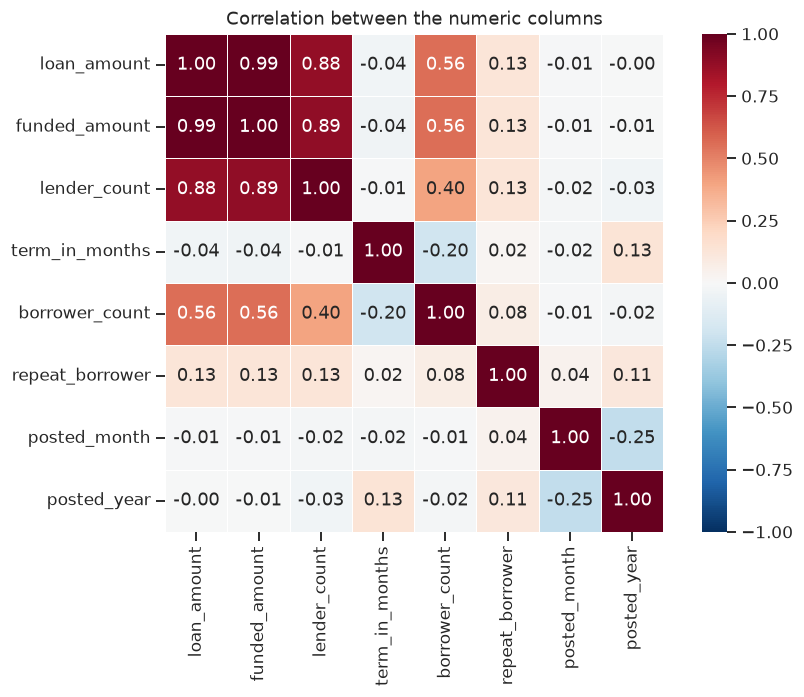

In [8]:
numeric = data[["loan_amount", "funded_amount", "lender_count", "term_in_months", "borrower_count", "repeat_borrower"]].copy()
numeric["posted_month"] = data["posted_time"].dt.month
numeric["posted_year"] = data["posted_time"].dt.year
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Correlation between the numeric columns")
plt.tight_layout()
plt.show()

**What I see.** `funded_amount` (0.99) and `lender_count` (0.88) move almost together with `loan_amount`. Of the inputs a woman knows before she applies, `borrower_count` has the strongest link (0.55), `repeat_borrower` a small positive one (0.13), and `term_in_months` is close to zero on its own. Month and year of posting have no real link with the amount.

**What I decide.** I drop `funded_amount` and `lender_count`: both are only known after lenders have funded the loan, so using them would leak the answer. I keep `borrower_count`, `repeat_borrower` and `term_in_months`. The term's weak straight-line correlation does not mean it is useless, because its effect depends on the country and the repayment schedule, which tree models can pick up. I drop month and year.

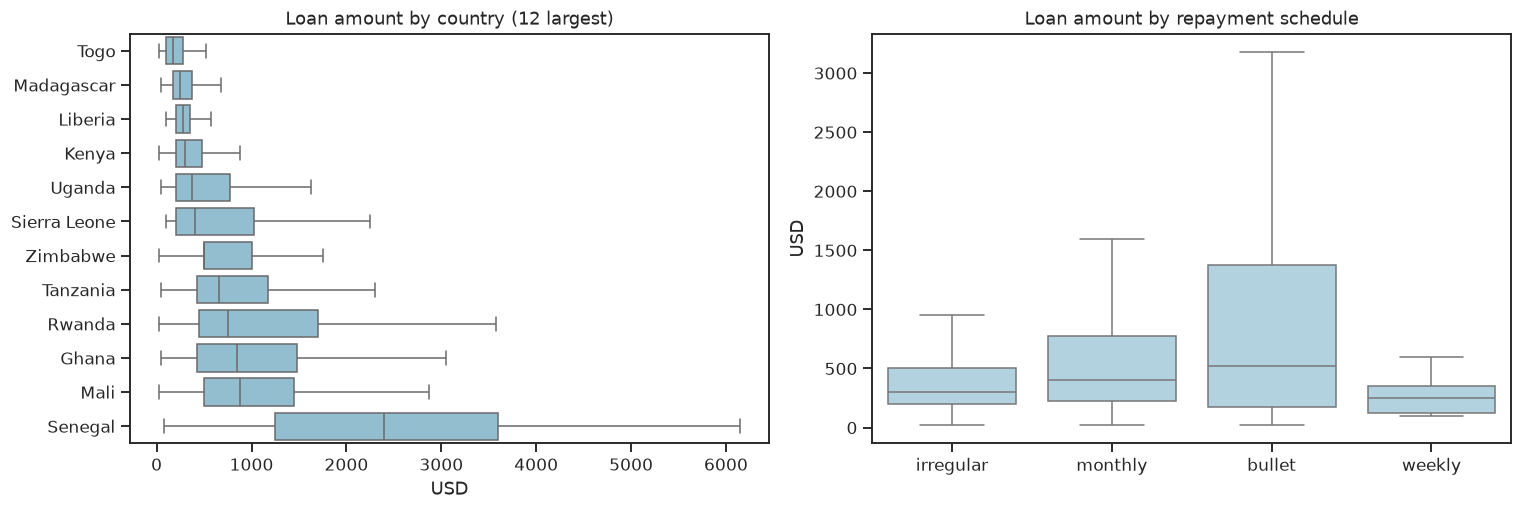

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
top_countries = data["country"].value_counts().head(12).index
order = data[data["country"].isin(top_countries)].groupby("country")["loan_amount"].median().sort_values().index
sns.boxplot(data=data[data["country"].isin(top_countries)], y="country", x="loan_amount", order=order,
            ax=axes[0], showfliers=False, color="#89c2d9")
axes[0].set(title="Loan amount by country (12 largest)", xlabel="USD", ylabel="")
sns.boxplot(data=data, x="repayment_interval", y="loan_amount", ax=axes[1], showfliers=False, color="#a9d6e5",
            order=["irregular", "monthly", "bullet", "weekly"])
axes[1].set(title="Loan amount by repayment schedule", xlabel="", ylabel="USD")
plt.tight_layout()
plt.show()

**What I see.** The country changes the typical loan size a lot: the median is under 200 dollars in Togo and about 2,300 dollars in Senegal. Bullet loans (paid back in one go at the end) are larger and more spread out than irregular or weekly loans.

**What I decide.** `country` and `repayment_interval` are both inputs. Because the country effect is so strong and there are 24 countries, the tree models get a target encoding of the country (its average log loan size), which keeps the data small.

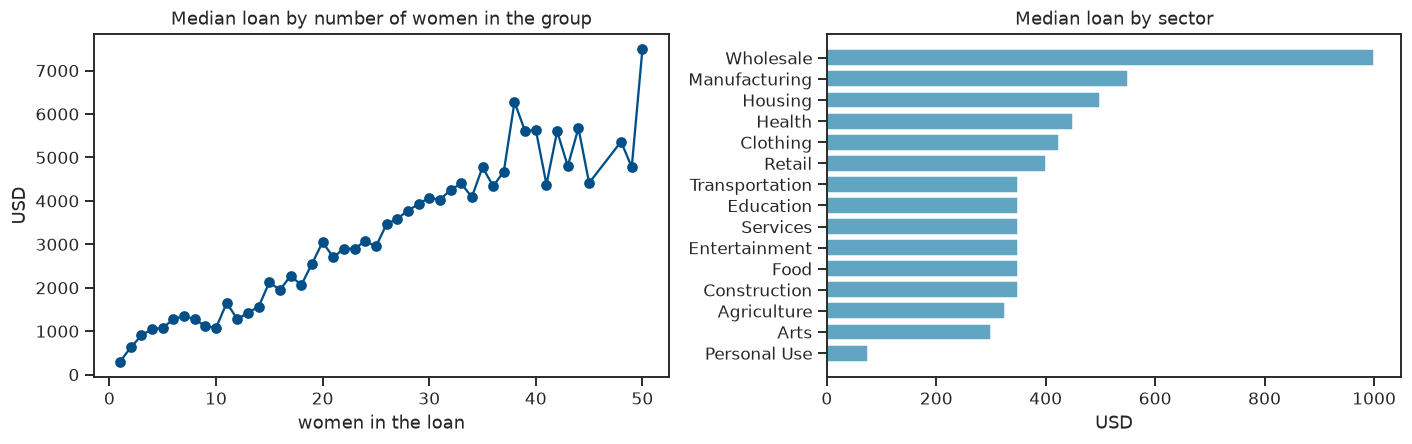

In [10]:
by_group = data.groupby("borrower_count")["loan_amount"].median()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(by_group.index, by_group.values, marker="o", color="#014f86")
axes[0].set(title="Median loan by number of women in the group", xlabel="women in the loan", ylabel="USD")
sector_median = data.groupby("sector")["loan_amount"].median().sort_values()
axes[1].barh(sector_median.index, sector_median.values, color="#61a5c2")
axes[1].set(title="Median loan by sector", xlabel="USD")
plt.tight_layout()
plt.show()

**What I see.** The median loan grows almost in a straight line with the number of women in the group, from about 300 dollars for one woman to over 4,000 dollars for groups of 30 or more. Sectors differ less: most sit between 300 and 500 dollars, with Wholesale higher and Personal Use much lower.

**What I decide.** `borrower_count` is the most important input. Since every activity belongs to one sector, I keep the more detailed `activity` and drop `sector`.

## 5. Choosing the inputs

| Column | Decision | Why |
|---|---|---|
| `country` | **input** | Loan sizes differ a lot between countries. |
| `activity` | **input** | The business (for example "Dairy", "Tailoring", "Retail"). 150 values. |
| `sector` | dropped | Each activity belongs to exactly one sector, so it repeats `activity`. |
| `repayment_interval` | **input** | Irregular, monthly, bullet or weekly. |
| `term_in_months` | **input** | Longer loans are larger. |
| `borrower_count` | **input** | Made from `borrower_genders`. The strongest single input. |
| `repeat_borrower` | **input** | Made from `tags`. A simple credit history signal. |
| `funded_amount`, `lender_count` | dropped | Only known after the loan is funded, so they leak the answer. |
| `partner_id` | dropped | An anonymous partner code that an entrepreneur would not know. In a first test it added only about 0.02 R². |
| `posted_time`, `funded_time`, `disbursed_time`, `date` | dropped | The data stops in 2017, so a date input cannot be used for today's requests. Year and month together added under 0.02 R². |
| `id`, `region`, `currency`, `country_code`, `tags`, `borrower_genders` | dropped | Ids, free text, or already turned into the features above. |

In [11]:
CATEGORICAL = ["country", "activity", "repayment_interval"]
NUMERIC = ["term_in_months", "borrower_count", "repeat_borrower"]
FEATURES = CATEGORICAL + NUMERIC

X = data[FEATURES]
y = np.log1p(data["loan_amount"])
X.sample(5, random_state=SEED)

,country,activity,repayment_interval,term_in_months,borrower_count,repeat_borrower
130570,Togo,Food Production/Sales,irregular,10.0,1,1
139439,Kenya,Cosmetics Sales,irregular,13.0,1,0
67575,Kenya,Agriculture,monthly,8.0,2,0
119263,Mozambique,Personal Housing Expenses,monthly,17.0,1,0
113515,Togo,Charcoal Sales,irregular,8.0,1,1


## 6. Splitting, encoding and scaling

* 80% of the loans train the models and 20% are kept as the test set. The test set is only used at the end, to compare the four models.
* For SGD tuning I take a further 15% of the training rows as a validation set.
* **Linear models** get one-hot encoding (activities seen fewer than 20 times are grouped into one "rare" column).
* **Tree models** get target encoding: each category is replaced by the average log loan size of that category, learned on the training rows with cross-fitting, so the test rows never leak into it.
* `StandardScaler` scales the three numeric inputs in both pipelines. Everything sits inside a scikit-learn `Pipeline`, so encoders and scaler are fitted on training rows only.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.15, random_state=SEED)
print(f"train {len(X_train):,} (fit {len(X_fit):,} + validation {len(X_val):,})  |  test {len(X_test):,}")

numeric_steps = Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())])


def linear_encoding():
    text_steps = Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                           ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20))])
    return ColumnTransformer([("num", numeric_steps, NUMERIC), ("cat", text_steps, CATEGORICAL)])


def tree_encoding():
    text_steps = Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                           ("target", TargetEncoder(cv=KFold(n_splits=5, shuffle=True, random_state=SEED)))])
    return ColumnTransformer([("num", numeric_steps, NUMERIC), ("cat", text_steps, CATEGORICAL)])


check = linear_encoding().fit(X_train)
print("One-hot matrix:", check.transform(X_train).shape, "| target-encoded matrix:", tree_encoding().fit_transform(X_train, y_train).shape)

train 81,485 (fit 69,262 + validation 12,223)  |  test 20,372


One-hot matrix: (81485, 129) | target-encoded matrix: (81485, 6)


In [13]:
def report(name, model, Xa=X_train, ya=y_train, Xb=X_test, yb=y_test):
    pa, pb = model.predict(Xa), model.predict(Xb)
    usd_true, usd_pred = np.expm1(yb), np.expm1(pb)
    return {"model": name,
            "train MSE": mean_squared_error(ya, pa),
            "test MSE": mean_squared_error(yb, pb),
            "test R2": r2_score(yb, pb),
            "test MAE (USD)": mean_absolute_error(usd_true, usd_pred),
            "median error %": float(np.median(np.abs(usd_pred - usd_true) / usd_true) * 100)}


baseline_mse = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
print(f"Baseline that always predicts the average training value: test MSE = {baseline_mse:.4f}")

Baseline that always predicts the average training value: test MSE = 0.8214


## 7. Model 1: linear regression trained with gradient descent (`SGDRegressor`)

I train with `partial_fit`, one shuffled pass over the data per epoch, and record the MSE after every pass. I tune on the validation set:

* **learning rate** `eta0`: 0.0005, 0.005, 0.05 (constant schedule)
* **regularisation strength** `alpha`: 0.00001, 0.001, 0.1
* **penalty type**: L2 (shrinks all weights) and L1 (can push weights to exactly zero)
* **epochs**: up to 60, keeping the best epoch

In [14]:
sgd_prep = linear_encoding().fit(X_fit)
A_fit, A_val = sgd_prep.transform(X_fit).tocsr(), sgd_prep.transform(X_val).tocsr()
t_fit, t_val = y_fit.to_numpy(), y_val.to_numpy()


def sgd_epochs(eta0, alpha, penalty, epochs, A, t, A_eval, t_eval):
    model = SGDRegressor(learning_rate="constant", eta0=eta0, alpha=alpha, penalty=penalty, random_state=SEED)
    shuffle = np.random.default_rng(SEED)
    history = {"train": [], "eval": []}
    for _ in range(epochs):
        idx = shuffle.permutation(A.shape[0])
        model.partial_fit(A[idx], t[idx])
        tr, ev = model.predict(A), model.predict(A_eval)
        if not np.isfinite(tr).all():
            history["train"].append(np.nan)
            history["eval"].append(np.nan)
            break
        history["train"].append(mean_squared_error(t, tr))
        history["eval"].append(mean_squared_error(t_eval, ev))
    return model, history


runs = []
for eta0 in [0.0005, 0.005, 0.05]:
    for alpha in [1e-5, 1e-3, 1e-1]:
        for penalty in ["l2", "l1"]:
            _, h = sgd_epochs(eta0, alpha, penalty, 60, A_fit, t_fit, A_val, t_val)
            ev = np.array(h["eval"], dtype=float)
            runs.append({"eta0": eta0, "alpha": alpha, "penalty": penalty,
                         "best epoch": int(np.nanargmin(ev)) + 1 if np.isfinite(ev).any() else None,
                         "best validation MSE": float(np.nanmin(ev)) if np.isfinite(ev).any() else np.inf,
                         "validation MSE at epoch 60": float(ev[-1]), "history": ev})

sgd_grid = pd.DataFrame(runs).sort_values("best validation MSE").reset_index(drop=True)
shown_grid = sgd_grid.drop(columns="history")
shown_grid["alpha"] = shown_grid["alpha"].map(lambda a: f"{a:g}")
shown_grid = shown_grid.round(4)
shown_grid

,eta0,alpha,penalty,best epoch,best validation MSE,validation MSE at epoch 60
0,0.0005,1e-05,l1,60,0.3491,0.3491
1,0.0005,1e-05,l2,60,0.3491,0.3491
2,0.0050,1e-05,l2,59,0.3506,0.3572
3,0.0050,1e-05,l1,59,0.3506,0.3572
4,0.0005,0.001,l1,60,0.3543,0.3543
5,0.0050,0.001,l2,45,0.3547,0.3607
6,0.0050,0.001,l1,45,0.3558,0.3626
7,0.0005,0.001,l2,60,0.3566,0.3566
8,0.0500,0.001,l1,27,0.3715,0.4013
9,0.0500,1e-05,l1,59,0.3770,0.4210


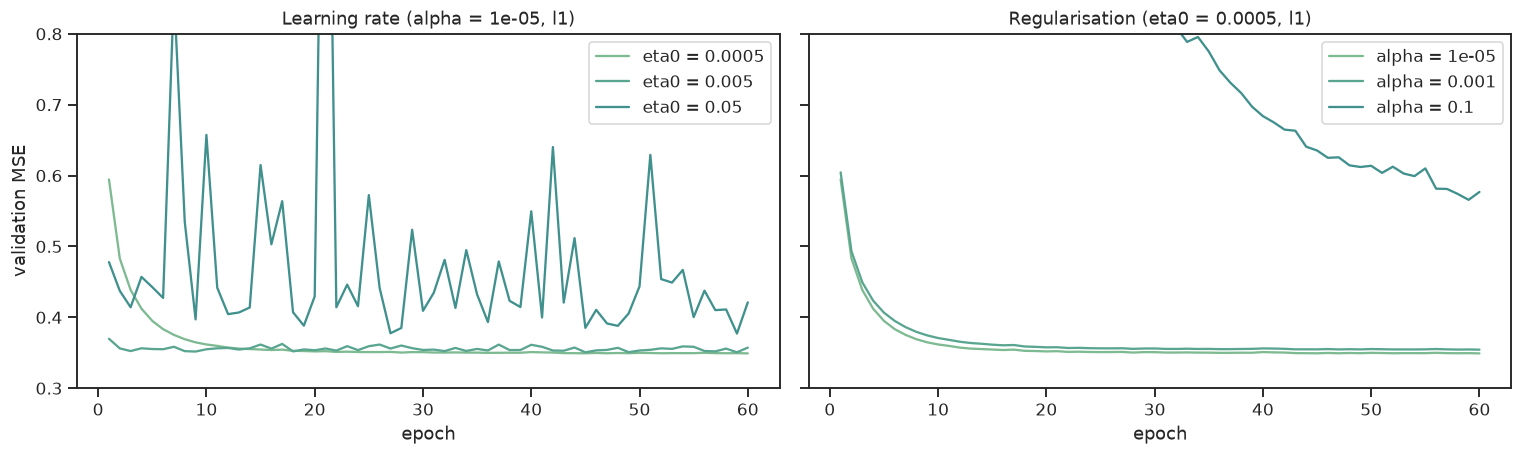

Best setting: {'eta0': np.float64(0.0005), 'alpha': np.float64(1e-05), 'penalty': 'l1', 'best epoch': np.int64(60)}


In [15]:
best = sgd_grid.iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), sharey=True)
for eta0 in [0.0005, 0.005, 0.05]:
    h = sgd_grid[(sgd_grid.eta0 == eta0) & (sgd_grid.alpha == best.alpha) & (sgd_grid.penalty == best.penalty)].iloc[0]["history"]
    axes[0].plot(range(1, len(h) + 1), h, label=f"eta0 = {eta0}")
axes[0].set(title=f"Learning rate (alpha = {best.alpha:g}, {best.penalty})", xlabel="epoch", ylabel="validation MSE")
axes[0].legend()
for alpha in [1e-5, 1e-3, 1e-1]:
    h = sgd_grid[(sgd_grid.eta0 == best.eta0) & (sgd_grid.alpha == alpha) & (sgd_grid.penalty == best.penalty)].iloc[0]["history"]
    axes[1].plot(range(1, len(h) + 1), h, label=f"alpha = {alpha:g}")
axes[1].set(title=f"Regularisation (eta0 = {best.eta0}, {best.penalty})", xlabel="epoch")
axes[1].legend()
axes[0].set_ylim(0.3, 0.8)
plt.tight_layout()
plt.show()
print("Best setting:", {k: best[k] for k in ["eta0", "alpha", "penalty", "best epoch"]})

**What tuning showed.**

* **Learning rate.** `eta0 = 0.05` is too large: the error drops fast but then bounces up again (0.37 at its best, 0.42 after 60 epochs). `eta0 = 0.005` and `0.0005` both reach about 0.35. The smallest rate learns more slowly but steadily and ends with the lowest error.
* **Regularisation strength.** `alpha = 0.1` pushes the weights too close to zero, and the error stays between 0.44 and 0.57. `alpha = 0.00001` gives the best results. With 69,000 rows and 129 columns, the model hardly needs a penalty.
* **Penalty type.** With a small alpha, L1 and L2 give the same error. With `alpha = 0.1`, L1 is clearly worse (about 0.54 against 0.44), because it sets many one-hot weights to zero.
* **Epochs.** The best setting is still improving very slightly at epoch 60, but by less than 0.001 per epoch, so 60 epochs is enough.

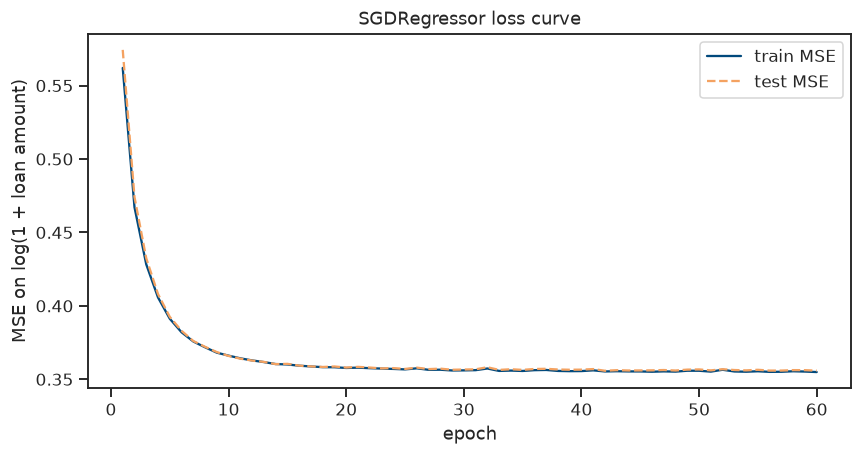

after epoch 1: train 0.5620 / test 0.5743   after epoch 60: train 0.3549 / test 0.3559


In [16]:
EPOCHS = int(best["best epoch"])
sgd_prep_full = linear_encoding().fit(X_train)
A_train, A_test = sgd_prep_full.transform(X_train).tocsr(), sgd_prep_full.transform(X_test).tocsr()
sgd_model, curve = sgd_epochs(best.eta0, best.alpha, best.penalty, EPOCHS, A_train, y_train.to_numpy(), A_test, y_test.to_numpy())
sgd_pipe = Pipeline([("encode", sgd_prep_full), ("model", sgd_model)])

plt.figure(figsize=(8, 4.3))
plt.plot(range(1, EPOCHS + 1), curve["train"], label="train MSE", color="#01497c")
plt.plot(range(1, EPOCHS + 1), curve["eval"], label="test MSE", color="#f4a261", linestyle="--")
plt.xlabel("epoch")
plt.ylabel("MSE on log(1 + loan amount)")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.tight_layout()
plt.show()
print(f"after epoch 1: train {curve['train'][0]:.4f} / test {curve['eval'][0]:.4f}   after epoch {EPOCHS}: train {curve['train'][-1]:.4f} / test {curve['eval'][-1]:.4f}")

The loss falls quickly in the first epochs (from about 0.57 at epoch 1) and then flattens out. Train and test MSE stay almost equal (0.355 and 0.356 at the end), so the model is not overfitting. The flat end of the curve shows that the straight-line model has reached its limit. More epochs will not help, but a model that can mix inputs together could.

## 8. Model 2: linear regression, closed form (`LinearRegression`)

In [17]:
ols_pipe = Pipeline([("encode", linear_encoding()), ("model", LinearRegression())]).fit(X_train, y_train)
pd.DataFrame([report("LinearRegression", ols_pipe)]).round(4)

,model,train MSE,test MSE,test R2,test MAE (USD),median error %
0,LinearRegression,0.3545,0.3557,0.5669,309.3722,37.5909


## 9. Model 3: decision tree, tuned with 3-fold cross-validation

In [18]:
tree_search = GridSearchCV(
    Pipeline([("encode", tree_encoding()), ("model", DecisionTreeRegressor(random_state=SEED))]),
    {"model__max_depth": [6, 10, 16, None], "model__min_samples_leaf": [5, 20, 60]},
    cv=3, scoring="neg_mean_squared_error", n_jobs=-1, return_train_score=True,
).fit(X_train, y_train)

tree_table = pd.DataFrame(tree_search.cv_results_)[["param_model__max_depth", "param_model__min_samples_leaf", "mean_train_score", "mean_test_score"]]
tree_table.columns = ["max_depth", "min_samples_leaf", "train MSE", "CV MSE"]
tree_table[["train MSE", "CV MSE"]] *= -1
tree_pipe = tree_search.best_estimator_
print("Best:", tree_search.best_params_)
tree_table.sort_values("CV MSE").round(4).head(8)

Best: {'model__max_depth': 16, 'model__min_samples_leaf': 20}


,max_depth,min_samples_leaf,train MSE,CV MSE
7,16,20,0.2237,0.2374
10,None,20,0.2256,0.2400
3,10,5,0.2338,0.2443
4,10,20,0.2380,0.2458
6,16,5,0.2229,0.2469
8,16,60,0.2402,0.2473
11,None,60,0.2405,0.2480
5,10,60,0.2497,0.2551


A depth of 6 is too shallow and leaves of 5 rows let the tree memorise noise. The best tree has a depth of 16 and at least 20 loans per leaf (CV MSE 0.237). Notice the gap between train and CV error: the tree fits the training rows a little better than new rows, which is the typical sign of a single tree starting to overfit.

## 10. Model 4: random forest, tuned with 3-fold cross-validation

I tune the number of trees, the maximum depth and the minimum leaf size. I also check the size of the saved file, because the API runs on a free Render instance with 512 MB of memory.

In [19]:
forest_search = GridSearchCV(
    Pipeline([("encode", tree_encoding()), ("model", RandomForestRegressor(random_state=SEED, n_jobs=-1))]),
    {"model__n_estimators": [30, 60], "model__max_depth": [12, 20], "model__min_samples_leaf": [5, 10]},
    cv=3, scoring="neg_mean_squared_error", n_jobs=1, return_train_score=True,
).fit(X_train, y_train)

forest_table = pd.DataFrame(forest_search.cv_results_)[["param_model__n_estimators", "param_model__max_depth",
                                                        "param_model__min_samples_leaf", "mean_train_score", "mean_test_score"]]
forest_table.columns = ["n_estimators", "max_depth", "min_samples_leaf", "train MSE", "CV MSE"]
forest_table[["train MSE", "CV MSE"]] *= -1
forest_pipe = forest_search.best_estimator_

buffer = io.BytesIO()
joblib.dump(forest_pipe, buffer, compress=3)
print("Best:", forest_search.best_params_, f"| saved size {buffer.tell() / 1e6:.1f} MB")
forest_table.sort_values("CV MSE").round(4)

Best: {'model__max_depth': 20, 'model__min_samples_leaf': 10, 'model__n_estimators': 60} | saved size 7.3 MB


,n_estimators,max_depth,min_samples_leaf,train MSE,CV MSE
7,60,20,10,0.2099,0.2242
5,60,20,5,0.2048,0.2242
6,30,20,10,0.2105,0.2247
1,60,12,5,0.2133,0.2248
4,30,20,5,0.2058,0.2251
0,30,12,5,0.2140,0.2255
3,60,12,10,0.2171,0.2266
2,30,12,10,0.2176,0.2273


All eight forests land close together (CV MSE 0.224 to 0.227), so the forest is not sensitive to these settings. Deeper trees (20) do a little better than depth 12, and 60 trees do a little better than 30. The best forest (60 trees, depth 20, at least 10 loans per leaf) saves to only about 7 MB, because target encoding gives the trees 6 compact columns instead of 129 one-hot columns. It is small enough for the free Render instance.

## 11. Comparing the four models on the same test set

In [20]:
candidates = {"SGDRegressor": sgd_pipe, "LinearRegression": ols_pipe, "DecisionTree": tree_pipe, "RandomForest": forest_pipe}
results = pd.DataFrame([report(name, m) for name, m in candidates.items()])
results.loc[len(results)] = {"model": "Baseline (average)", "train MSE": mean_squared_error(y_train, np.full(len(y_train), y_train.mean())),
                             "test MSE": baseline_mse, "test R2": 0.0,
                             "test MAE (USD)": mean_absolute_error(np.expm1(y_test), np.full(len(y_test), np.expm1(y_train.mean()))),
                             "median error %": float(np.median(np.abs(np.expm1(y_train.mean()) - np.expm1(y_test)) / np.expm1(y_test)) * 100)}
results = results.sort_values("test MSE").reset_index(drop=True)
results.round({"train MSE": 4, "test MSE": 4, "test R2": 3, "test MAE (USD)": 0, "median error %": 1})

,model,train MSE,test MSE,test R2,test MAE (USD),median error %
0,RandomForest,0.2111,0.2252,0.726,206.0,26.4
1,DecisionTree,0.2179,0.2322,0.717,211.0,27.4
2,LinearRegression,0.3545,0.3557,0.567,309.0,37.6
3,SGDRegressor,0.3549,0.3559,0.567,311.0,37.6
4,Baseline (average),0.8272,0.8214,0.000,416.0,54.4


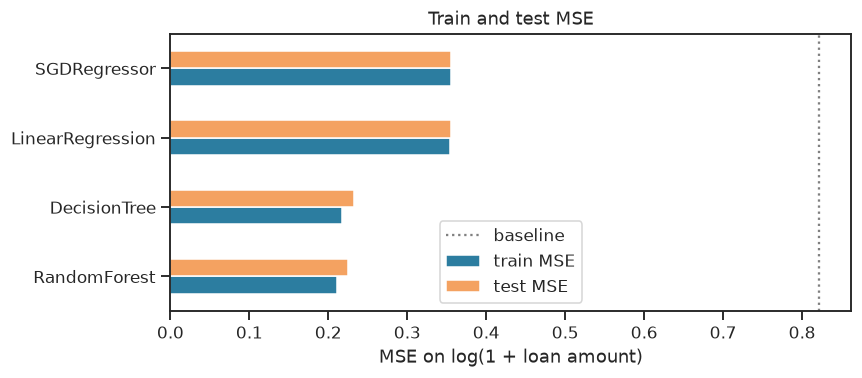

Lowest test MSE: RandomForest (0.2252, R2 0.726)
Deployment rule: R2 >= 0.6 and MSE <= 50% of baseline -> passed


In [21]:
shown = results[results.model != "Baseline (average)"]
ax = shown.set_index("model")[["train MSE", "test MSE"]].plot.barh(figsize=(8, 3.6), color=["#2c7da0", "#f4a261"])
ax.axvline(baseline_mse, color="grey", linestyle=":", label="baseline")
ax.set(xlabel="MSE on log(1 + loan amount)", ylabel="", title="Train and test MSE")
ax.legend()
plt.tight_layout()
plt.show()

best_name = shown.iloc[0]["model"]
best_row = shown.iloc[0]
MIN_R2, MAX_RATIO = 0.60, 0.50
ok = best_row["test R2"] >= MIN_R2 and best_row["test MSE"] <= MAX_RATIO * baseline_mse
print(f"Lowest test MSE: {best_name} ({best_row['test MSE']:.4f}, R2 {best_row['test R2']:.3f})")
print(f"Deployment rule: R2 >= {MIN_R2} and MSE <= {MAX_RATIO:.0%} of baseline -> {'passed' if ok else 'FAILED'}")

**Best model: random forest.** It has the lowest test MSE (0.225 on the log scale, R² 0.726). In dollars, half of its estimates are within 26% of the real loan amount. The decision tree is close behind (0.232), and the two linear models are clearly weaker (about 0.356 each, R² 0.567).

**How the data explains this result.** The amount a woman raises depends on combinations of inputs: a 12-month monthly loan in Senegal is a different thing from the same loan in Togo, and group size adds money in steps that are not a straight line (see the scatter plot below). A linear model gives each input one fixed weight, so it cannot capture these combinations. Trees split on country, then group size, then term, and so learn them directly. The forest averages 60 trees built on different samples of loans, which smooths out the noise a single tree picks up. SGD ends at the same error as the closed-form `LinearRegression` (0.3559 against 0.3557), which shows that gradient descent found the least-squares solution.

**Deployment rule.** The model I save must clearly beat the baseline that always predicts the average: R² of at least 0.60 and a test MSE of at most half the baseline. The forest's MSE is 27% of the baseline, so it passes. `/retrain` uses the same rule before it swaps models.

## 12. Scatter plot before and after fitting a line

Correlation of each numeric input with log loan amount:
borrower_count     0.505
repeat_borrower    0.240
term_in_months     0.097


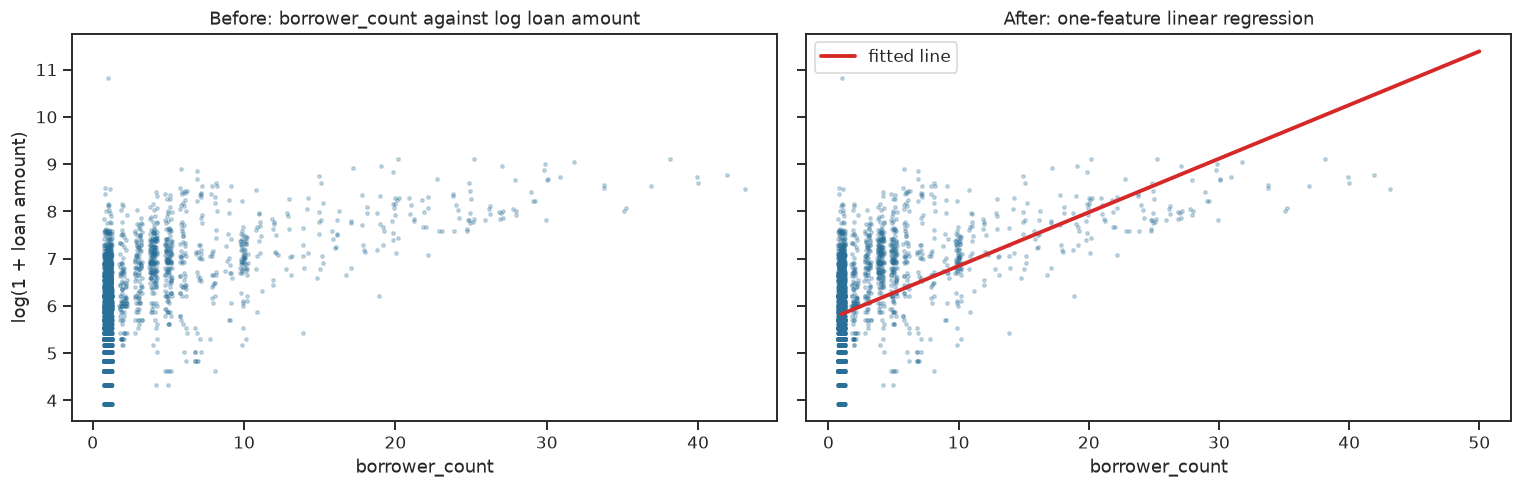

Each extra woman in the group adds 0.114 to the log amount, about 12% more money


In [22]:
corr_with_target = data[NUMERIC].corrwith(np.log1p(data["loan_amount"])).abs().sort_values(ascending=False)
top = corr_with_target.index[0]
print("Correlation of each numeric input with log loan amount:")
print(corr_with_target.round(3).to_string())

line = LinearRegression().fit(X_train[[top]], y_train)
xs = np.linspace(X[top].min(), X[top].max(), 50)
sample = X_train.sample(5000, random_state=SEED)
jitter = np.random.default_rng(SEED).uniform(-0.25, 0.25, len(sample))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax in axes:
    ax.scatter(sample[top] + jitter, y_train[sample.index], s=5, alpha=0.25, color="#2a6f97")
    ax.set(xlabel=top)
axes[0].set(title=f"Before: {top} against log loan amount", ylabel="log(1 + loan amount)")
axes[1].plot(xs, line.predict(pd.DataFrame({top: xs})), color="#d62828", linewidth=2.5, label="fitted line")
axes[1].set(title="After: one-feature linear regression")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"Each extra woman in the group adds {line.coef_[0]:.3f} to the log amount, about {np.expm1(line.coef_[0]):.0%} more money")

`borrower_count` is the numeric input most linked to the loan size (correlation 0.51). The fitted line says that each extra woman in a group adds about 12% to the loan. The line also shows the limit of a straight-line model. Most loans have one borrower and the points there spread over a wide range, while for large groups the line keeps climbing above the real points, because loans grow more slowly once groups pass about 20 women. The tree models do not have this problem.

## 13. Which inputs matter most

I use permutation importance on 5,000 test rows: shuffle one input at a time and measure how much the random forest's test MSE gets worse. Unlike impurity-based importance, this works the same for every kind of input.

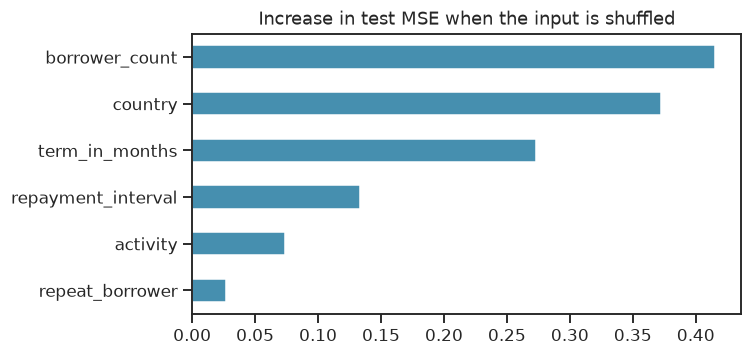

borrower_count        0.4154
country               0.3725
term_in_months        0.2734
repayment_interval    0.1335
activity              0.0738
repeat_borrower       0.0270


In [23]:
rows = X_test.sample(5000, random_state=SEED)
perm = permutation_importance(forest_pipe, rows, y_test[rows.index], scoring="neg_mean_squared_error", n_repeats=5, random_state=SEED, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
importance.plot.barh(figsize=(7, 3.4), color="#468faf", title="Increase in test MSE when the input is shuffled")
plt.tight_layout()
plt.show()
print(importance.sort_values(ascending=False).round(4).to_string())

Shuffling `borrower_count` hurts the forest the most, then `country` and `term_in_months`. The repayment schedule and the activity matter less, and the repeat-borrower flag least. So the size of a woman's group and where she lives say more about the loan she can raise than what she sells. This fits the mission: group lending through cooperatives and women's groups is one of the strongest signals available, even with no bank history.

## 14. Saving the best model

The saved object is a `TransformedTargetRegressor`: it wraps the full pipeline (imputers, encoders, scaler, model) and turns the log prediction back into dollars, so the API gets a dollar amount straight from `predict`. Next to it I save the valid choices for the text inputs and the training and test rows that `/retrain` needs.

In [24]:
from sklearn.base import clone

# Same settings as the winning pipeline, fitted on dollars: the wrapper takes log1p inside and returns dollars.
deployable = TransformedTargetRegressor(regressor=clone(candidates[best_name]), func=np.log1p,
                                        inverse_func=np.expm1, check_inverse=False)
deployable.fit(X_train, data.loc[X_train.index, "loan_amount"])
check_mse = mean_squared_error(y_test, np.log1p(deployable.predict(X_test)))
print(f"Refitted {best_name}: test MSE {check_mse:.4f} (same model as in the table)")

bundle = {
    "model": deployable,
    "model_name": best_name,
    "version": 1,
    "features": FEATURES,
    "choices": {"country": sorted(data["country"].unique()), "activity": sorted(data["activity"].unique()),
                "repayment_interval": ["bullet", "irregular", "monthly", "weekly"]},
    "sector_of_activity": data.groupby("activity")["sector"].first().to_dict(),
    "test_metrics": {k: float(best_row[k]) for k in ["test MSE", "test R2", "test MAE (USD)", "median error %"]},
    "baseline_mse": float(baseline_mse),
    "rule": {"min_r2": MIN_R2, "max_ratio_to_baseline": MAX_RATIO},
}
joblib.dump(bundle, API / "best_model.pkl", compress=3)

keep = FEATURES + ["loan_amount"]
data.loc[X_train.index, keep].to_csv(API / "data" / "train_rows.csv.gz", index=False)
data.loc[X_test.index, keep].to_csv(API / "data" / "test_rows.csv.gz", index=False)
print(f"Saved best_model.pkl ({(API / 'best_model.pkl').stat().st_size / 1e6:.1f} MB), {len(X_train):,} training rows and {len(X_test):,} test rows")

Refitted RandomForest: test MSE 0.2252 (same model as in the table)


Saved best_model.pkl (7.3 MB), 81,485 training rows and 20,372 test rows


## 15. Predicting one loan from the test set

The API's `/predict` route calls the same function, which loads the saved file and returns dollars.

In [25]:
def predict_loan_size(applicant, model_file=API / "best_model.pkl"):
    saved = joblib.load(model_file)
    row = pd.DataFrame([applicant], columns=saved["features"])
    return float(saved["model"].predict(row)[0])


applicant = X_test.iloc[3].to_dict()
estimate = predict_loan_size(applicant)
actual = float(np.expm1(y_test.iloc[3]))
print("Applicant:", applicant)
print(f"Estimated loan size: ${estimate:,.0f}   |   actual: ${actual:,.0f}")

Applicant: {'country': 'Mozambique', 'activity': 'Personal Housing Expenses', 'repayment_interval': 'monthly', 'term_in_months': 17.0, 'borrower_count': 1, 'repeat_borrower': 0}
Estimated loan size: $490   |   actual: $225


In [26]:
few = X_test.sample(6, random_state=21).copy()
few["actual USD"] = np.expm1(y_test[few.index]).round(0)
few["estimate USD"] = [round(predict_loan_size(r), 0) for r in few[FEATURES].to_dict("records")]
few

,country,activity,repayment_interval,term_in_months,borrower_count,repeat_borrower,actual USD,estimate USD
81239,Kenya,Clothing Sales,irregular,13.0,1,0,775.0,303.0
16611,Kenya,Home Energy,monthly,14.0,1,0,1150.0,87.0
143107,Senegal,Beauty Salon,monthly,8.0,12,0,1150.0,1818.0
131962,Madagascar,Pigs,monthly,8.0,1,0,200.0,426.0
134901,Togo,Home Products Sales,irregular,11.0,1,0,275.0,271.0
91266,Kenya,Beauty Salon,monthly,8.0,1,0,300.0,214.0


## 16. Summary and answers I use in the video

* **Data.** 101,857 women-led Kiva loans from 24 African countries (2014 to May 2017), 6 inputs, target `log(1 + loan_amount)`. The 3,602 newest loans (June and July 2017) are saved in `API/sample_new_loans.csv` to test retraining.
* **Best model.** Random forest: test MSE 0.225, R² 0.726, half of the estimates within 26% of the real amount. Saved with all its preprocessing in `API/best_model.pkl`.
* **Is the loss high or low?** Low enough to be useful. The baseline MSE is 0.82 and the forest removes about 73% of it. A 26% typical error means a 400 dollar loan is usually estimated between about 300 and 500 dollars, which is precise enough to tell a woman whether her request is in a realistic range, but not to set an exact loan. To lower it, I would add the inputs my mission is really about: mobile money history (monthly inflows, savings balance), cooperative membership and repayment records, which Kiva does not contain.
* **Hyperparameters.** For SGD: learning rate, regularisation strength, penalty type and number of epochs (Section 7). For the trees: depth, leaf size and number of trees, chosen with 3-fold cross-validation.
* **Limits.** The data stops in 2017 and amounts are in 2014 to 2017 US dollars. The model describes what Kiva lenders funded, not what a woman can repay, so it should guide the size of a request, not decide who gets credit.